
========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.6
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.6

Iniciando entrenamiento...
Época 01/10 | Train MSE: 0.02737 | Valid MSE: 0.02754
Época 02/10 | Train MSE: 0.02315 | Valid MSE: 0.02334
Época 03/10 | Train MSE: 0.02129 | Valid MSE: 0.02148
Época 04/10 | Train MSE: 0.02051 | Valid MSE: 0.02072
Época 05/10 | Train MSE: 0.02005 | Valid MSE: 0.02026
Época 06/10 | Train MSE: 0.01942 | Valid MSE: 0.01962
Época 07/10 | Train MSE: 0.01887 | Valid MSE: 0.01907
Época 08/10 | Train MSE: 0.01887 | Valid MSE: 0.01908
Época 09/10 | Train MSE: 0.01855 | Valid MSE: 0.01874
Época 10/10 | Train MSE: 0.01851 | Valid MSE: 0.01871
Training time: 78.33 seconds

Test MSE: 0.01861


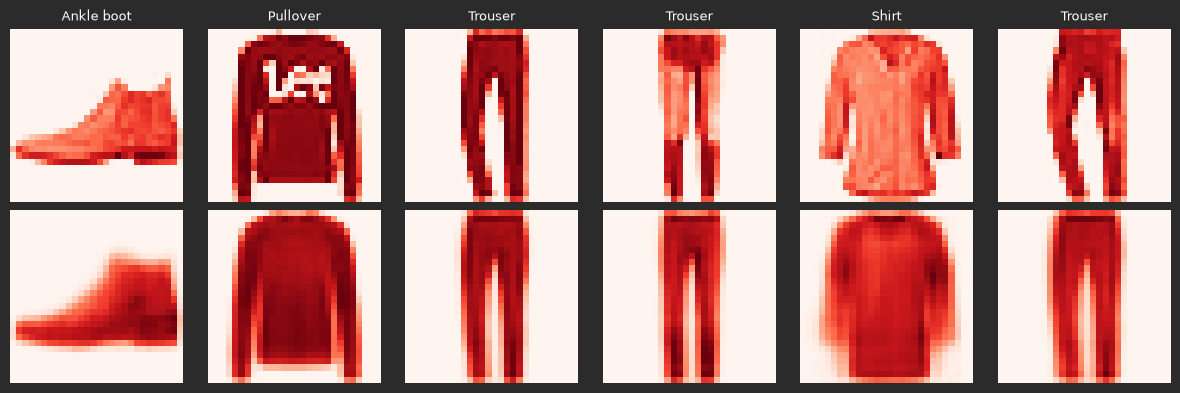


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.1
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.1

Iniciando entrenamiento...
Época 01/10 | Train MSE: 0.02024 | Valid MSE: 0.02042
Época 02/10 | Train MSE: 0.01439 | Valid MSE: 0.01455
Época 03/10 | Train MSE: 0.01255 | Valid MSE: 0.01272
Época 04/10 | Train MSE: 0.01132 | Valid MSE: 0.01150
Época 05/10 | Train MSE: 0.01063 | Valid MSE: 0.01081
Época 06/10 | Train MSE: 0.01021 | Valid MSE: 0.01040
Época 07/10 | Train MSE: 0.00987 | Valid MSE: 0.01007
Época 08/10 | Train MSE: 0.00964 | Valid MSE: 0.00985
Época 09/10 | Train MSE: 0.00951 | Valid MSE: 0.00973
Época 10/10 | Train MSE: 0.00926 | Valid MSE: 0.00948
Training time: 72.71 seconds

Test MSE: 0.00942


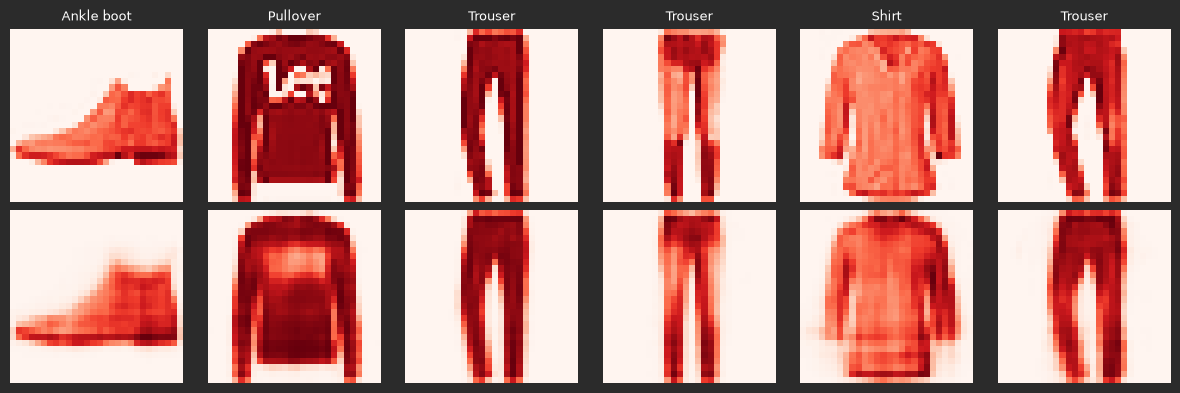


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.1
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.1

Iniciando entrenamiento...
Época 01/10 | Train MSE: 0.02024 | Valid MSE: 0.02042
Época 02/10 | Train MSE: 0.01439 | Valid MSE: 0.01455
Época 03/10 | Train MSE: 0.01255 | Valid MSE: 0.01272
Época 04/10 | Train MSE: 0.01132 | Valid MSE: 0.01150
Época 05/10 | Train MSE: 0.01063 | Valid MSE: 0.01081


In [ ]:
import time

import torch
from torch import nn

from extra.Guia10Reformat.src.Config import Config
from extra.Guia10Reformat.src.FashionMNISTDATA import FashionMNISTData
from src.Autoencoder import Autoencoder
from src.Optimizer import create_optimizer
from src.Trainer import Trainer
from src.Visualizer import Visualizer


def main(config):
    # Configuración
    device = config.setup()
    # Datos
    data = FashionMNISTData(
        batch_size=config.BATCH_SIZE,
        seed=config.SEED, color=config.COLOR
    )

    if config.showSample:
        data.inspect_example()
        data.show_samples()

    # Modelo
    torch.manual_seed(Config.SEED)

    model = Autoencoder(
        latent_dim=config.LATENT_DIM,
        p_dropout=config.DROPOUT_P
    ).to(device)

    # Comprobar dimensiones
    if config.showDimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            reconstructions = model(images.to(device))
            latent_codes = model.encode(images.to(device))

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Código latente:", latent_codes.shape)
        print("Reconstrucción:", reconstructions.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.MSELoss()

    optimizer = create_optimizer(
        model,
        config.OPTIMIZER_NAME
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Reconstrucciones antes del entrenamiento
    if config.showUntrained:
        Visualizer.show_reconstructions(
            model,
            data.valid_loader,
            device,
            data.CLASS_NAMES,
            title="Sin entrenar", color=config.COLOR
        )

    # Entrenamiento
    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    print(f"Training time: {time.perf_counter() - start:.2f} seconds")
    # Gráfico de pérdidas
    if config.showLoss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    trainer.test(data.test_loader)

    # Reconstrucciones después del entrenamiento
    if config.showTrained: Visualizer.show_reconstructions(
        model,
        data.test_loader,
        device,
        data.CLASS_NAMES,
        title="Reconstrucción", color=config.COLOR
    )

    # Espacio latente
    if config.showDimentions2:
        images, _ = next(iter(data.test_loader))

        images = images.to(device)

        model.eval()

        with torch.no_grad():
            latent_codes = model.encode(images)

        print("\nEspacio latente:")
        print("Imágenes:", images.shape)
        print("Códigos latentes:", latent_codes.shape)


# ============================================================
# EJECUCIÓN
# ============================================================

if __name__ == "__main__":
    config1 = Config(latent_dim=128, dropout_p=0.5, showSample=False, showDimentions=False, showUntrained=False,
                     showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

    config2 = Config(latent_dim=128, dropout_p=0.0, showSample=False, showDimentions=False, showUntrained=False,
                     showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

    config3 = Config(latent_dim=128, dropout_p=0.0, optimizer_name="SGD", showSample=False, showDimentions=False,
                     showUntrained=False,
                     showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

    toRun = [config1, config2, config2]
    for config in toRun:
        main(config)
